# Soil moisture evolution around NO$_2$ pulses, pulses at/after 10:00 local


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DIR = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/"+ ("final_datasets_excl")
SOIL_FILE = "/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_merged_all_datasets_allcols_MCD12Q1mask_2024.parquet"   # any parquet with grid_lat, grid_lon and the pct_* texture fractions
YEARS = [2024, 2025]
HOUR_MIN = 10
THRESHOLD = 0.7        #  dominant texture must cover >= 70% of the cell

soil_cols = ["pct_clay", "pct_clay_loam", "pct_loam", "pct_loamy_sand", "pct_sand", "pct_sandy_clay", "pct_sandy_clay_loam",
             "pct_sandy_loam", "pct_silt", "pct_silt_loam", "pct_silty_clay", "pct_silty_clay_loam"]
soil_group_map = {"sand": "coarse",
                  "loamy_sand": "moderately_coarse", "sandy_loam": "moderately_coarse",
                  "loam": "medium", "silt_loam": "medium", "silt": "medium",
                  "clay_loam": "fine", "silty_clay_loam": "fine", "sandy_clay_loam": "fine",
                  "clay": "fine", "silty_clay": "fine", "sandy_clay": "fine"}
soil_group_order = ["coarse", "moderately_coarse", "medium", "fine"]
group_palette = {"coarse": "blue", "moderately_coarse": "green", "medium": "darkgoldenrod", "fine": "red"}
sm_colors = {"increasing": "cornflowerblue", "decreasing": "orange"}

cm = 1 / 2.54
fig_width, fig_height = 8.7 * cm, 18 * cm
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size": 7, "axes.labelsize": 7, "axes.titlesize": 8, "xtick.labelsize": 6, "ytick.labelsize": 6,
                     "legend.fontsize": 6, "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 600})

## Texture fractions per grid cell

In [4]:
tex = (pd.read_parquet(SOIL_FILE, columns=["grid_lat", "grid_lon"] + soil_cols)
       .assign(grid_lat=lambda d: d["grid_lat"].astype(float).round(2), grid_lon=lambda d: d["grid_lon"].astype(float).round(2))
       .drop_duplicates(["grid_lat", "grid_lon"]))
tex[soil_cols] = tex[soil_cols] / 100         
print(f"texture fractions for {len(tex):,} grid cells")

def load_year(y):
    d = pd.read_parquet(f"{DIR}/lowCF_7day_events_long_MCD12Q1mask_{y}.parquet", engine="pyarrow")
    d["datetime_local"] = pd.to_datetime(d["datetime_local"])
    start_hour = d.loc[d["lag_days"] == 0].groupby("event_id")["datetime_local"].first().dt.hour   # local hour of the pulse start
    keep = start_hour[start_hour >= HOUR_MIN].index
    d = d[d["event_id"].isin(keep)].assign(year=y)
    d["grid_lat"], d["grid_lon"] = d["grid_lat"].astype(float).round(2), d["grid_lon"].astype(float).round(2)
    d = d.drop(columns=[c for c in soil_cols if c in d.columns]).merge(tex, on=["grid_lat", "grid_lon"], how="left")
    have = d.drop_duplicates("event_id")[soil_cols].notna().all(axis=1).mean()
    print(f"{y}: {len(keep):,} of {start_hour.size:,} events start at or after {HOUR_MIN}:00 local | {have:.0%} have texture fractions")
    return d

data = {str(y): load_year(y) for y in YEARS}
data["2024-2025"] = pd.concat([data[str(y)] for y in YEARS], ignore_index=True)   # pooled: every event weighted equally

texture fractions for 10,480 grid cells
2024: 3,764 of 15,887 events start at or after 10:00 local | 100% have texture fractions
2025: 3,611 of 17,740 events start at or after 10:00 local | 100% have texture fractions


## Figure: overall + by soil group

In [5]:
def soil_groups(events_long):
    df = events_long.dropna(subset=soil_cols, how="all").copy()
    df["dominant_soil"] = df[soil_cols].idxmax(axis=1).str.replace("pct_", "")
    df["max_frac"] = df[soil_cols].max(axis=1)
    df_endmembers = df[df["max_frac"] >= THRESHOLD].copy()
    counts = df_endmembers["dominant_soil"].value_counts()
    df_endmembers = df_endmembers[df_endmembers["dominant_soil"].isin(counts[counts > 50].index)].copy()
    df_endmembers["soil_group"] = df_endmembers["dominant_soil"].map(soil_group_map)
    return df_endmembers[df_endmembers["soil_group"].notna() & df_endmembers["sm_class"].isin(["increasing", "decreasing"])
                         ].dropna(subset=["lag_days", "WFPS_c"]).copy()

def plot_sm(events_long, tag):
    ev = ["year", "event_id"]                     
    plot_df = events_long[events_long["sm_class"].isin(["increasing", "decreasing"])].dropna(subset=["lag_days", "WFPS_c", "sm_class"])
    df_end = soil_groups(events_long)
    n = (df_end.drop_duplicates(ev).groupby(["soil_group", "sm_class"]).size().unstack(fill_value=0)
         .reindex(index=soil_group_order, columns=["increasing", "decreasing"], fill_value=0))
    total = n.sum(axis=1)
    table = pd.DataFrame({"Soil Texture Group": [g.replace("_", " ").title() for g in n.index],
                          "Increasing %": (100 * n["increasing"] / total).round(1).to_numpy(),
                          "Decreasing %": (100 * n["decreasing"] / total).round(1).to_numpy(),
                          "Total n": total.astype(int).to_numpy()})
    print(f"{tag}: event composition by soil texture group")
    display(table.style.hide(axis="index").format({"Increasing %": "{:.1f}", "Decreasing %": "{:.1f}"}))
    table.to_csv(f"event_composition_{tag}_{HOUR_MIN}am_herslogic.csv", index=False)

    fig, (ax1, ax3, ax4) = plt.subplots(3, 1, figsize=(fig_width, fig_height))
    fig.subplots_adjust(hspace=0.45)

    #panel a overall
    summary = plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"].agg(["mean", "std", "count"]).reset_index()
    summary["sem"] = summary["std"] / np.sqrt(summary["count"])
    for cls in ["increasing", "decreasing"]:
        sub = summary[summary["sm_class"] == cls]
        ax1.plot(sub["lag_days"], sub["mean"], label=cls, color=sm_colors[cls], linewidth=1.5)
        ax1.fill_between(sub["lag_days"], sub["mean"] - sub["sem"], sub["mean"] + sub["sem"], color=sm_colors[cls], alpha=0.20)
    ax1.axvline(0, linestyle="--", linewidth=0.8, color="gray")
    ax1.set_xlim(-7, 5); ax1.set_xlabel("Days Relative to NO$_2$ Pulse"); ax1.set_ylabel("WFPS")
    ax1.set_title("A Overall soil moisture evolution", loc="left")
    ax1.grid(True, alpha=0.3)

    #panels b and c by soil group
    for ax, cls, label in [(ax3, "increasing", "B Increasing cases by soil type"), (ax4, "decreasing", "C Decreasing cases by soil type")]:
        s = df_end[df_end["sm_class"] == cls].groupby(["soil_group", "lag_days"])["WFPS_c"].agg(["mean", "std", "count"]).reset_index()
        s["sem"] = s["std"] / np.sqrt(s["count"])
        for grp in soil_group_order:
            g = s[s["soil_group"] == grp]
            if g.empty:
                continue
            ax.plot(g["lag_days"], g["mean"], color=group_palette[grp], linewidth=1.5, label=grp.replace("_", " "))
            ax.fill_between(g["lag_days"], g["mean"] - g["sem"], g["mean"] + g["sem"], color=group_palette[grp], alpha=0.18)
        ax.axvline(0, linestyle="--", linewidth=0.8, color="gray")
        ax.set_xlim(-7, 5); ax.set_title(label, loc="left")
        ax.set_xlabel("Days Relative to NO$_2$ Pulse"); ax.set_ylabel("WFPS"); ax.grid(True, alpha=0.3)

    lo = min(ax3.get_ylim()[0], ax4.get_ylim()[0]); hi = max(ax3.get_ylim()[1], ax4.get_ylim()[1])
    ax3.set_ylim(lo, hi); ax4.set_ylim(lo, hi)
    fig.subplots_adjust(bottom=0.115, top=0.97, left=0.15, right=0.97)
    handles, labels = ax3.get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.55, 0.0), title="Soil Type")
    fig.savefig(f"Composite_soil_moisture_{tag}_{HOUR_MIN}am_herslogic.pdf", bbox_inches="tight", dpi=600)
    plt.show()

2024: event composition by soil texture group


Soil Texture Group,Increasing %,Decreasing %,Total n
Coarse,nan,nan,0
Moderately Coarse,32.6,67.4,95
Medium,33.3,66.7,1699
Fine,39.1,60.9,483


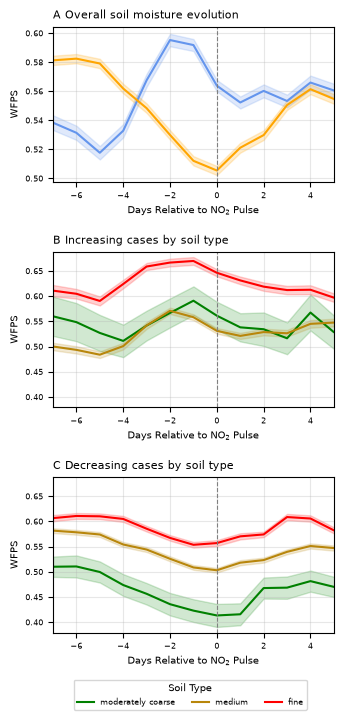

In [6]:
plot_sm(data["2024"], "2024")

2025: event composition by soil texture group


Soil Texture Group,Increasing %,Decreasing %,Total n
Coarse,nan,nan,0
Moderately Coarse,39.3,60.7,117
Medium,29.8,70.2,1343
Fine,19.4,80.6,607


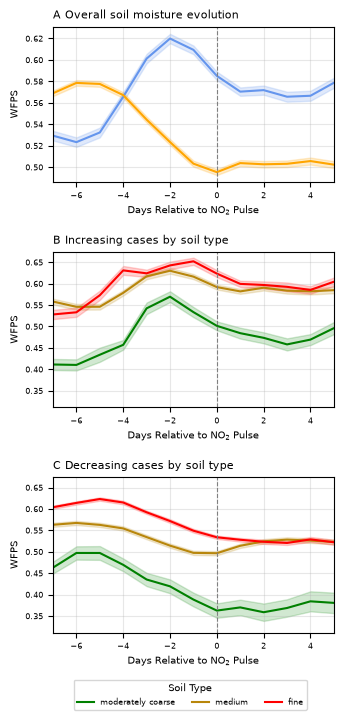

In [7]:
plot_sm(data["2025"], "2025")

2024-2025: event composition by soil texture group


Soil Texture Group,Increasing %,Decreasing %,Total n
Coarse,nan,nan,0
Moderately Coarse,36.3,63.7,212
Medium,31.7,68.3,3042
Fine,28.1,71.9,1091


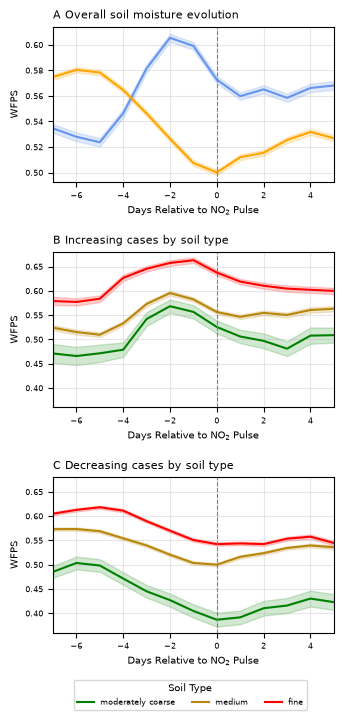

In [8]:
plot_sm(data["2024-2025"], "2024-2025")